# H&M 상품 및 고객 분석
상품 메타데이터 105,542행과 구매 데이터 앞 200,000행(2018-09-20~24)을 사용한다. 기간이 짧아 전체 고객이나 장기 이탈로 일반화하지 않는다. 가격은 원 데이터의 정규화 값이며 통화 단위로 해석하지 않는다. 이미지 피처는 확보한 상품 사진 40장에 한정한다.

In [1]:
# 라이브러리와 분석 클래스를 불러온다.
from pathlib import Path
import sys
import numpy as 넘파이
import pandas as 판다스
import matplotlib.pyplot as 그래프
import matplotlib.image as 이미지읽기
import seaborn as 시본
프로젝트경로 = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(프로젝트경로 / 'src'))
from analyzer import DataAnalyzer
판다스.set_option('display.max_columns', 12)

## 데이터 불러오기와 기본 탐색

In [2]:
# 상품 데이터와 거래 표본을 읽는다.
상품분석기 = DataAnalyzer(프로젝트경로 / 'data/raw/hm/articles.csv')
상품표 = 상품분석기.load_data()
거래표 = 판다스.read_csv(프로젝트경로 / 'data/raw/hm/transactions_sample_200000.csv')
상품표['article_id'] = 상품표['article_id'].astype(str).str.zfill(10)
거래표['article_id'] = 거래표['article_id'].astype(str).str.zfill(10)
거래표['t_dat'] = 판다스.to_datetime(거래표['t_dat'])
print('상품 행·열:', 상품표.shape, '거래 행·열:', 거래표.shape)
상품표.head()

상품 행·열: (105542, 25) 거래 행·열: (200000, 5)


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,...,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,0108775015,108775,Strap top,253,Vest top,Garment Upper body,...,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,0108775044,108775,Strap top,253,Vest top,Garment Upper body,...,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,0108775051,108775,Strap top (1),253,Vest top,Garment Upper body,...,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,0110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,...,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,0110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,...,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [3]:
상품표.info()
상품표.describe(include='all').T.head(8)

<class 'pandas.DataFrame'>
RangeIndex: 105542 entries, 0 to 105541
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype
---  ------                        --------------   -----
 0   article_id                    105542 non-null  str  
 1   product_code                  105542 non-null  int64
 2   prod_name                     105542 non-null  str  
 3   product_type_no               105542 non-null  int64
 4   product_type_name             105542 non-null  str  
 5   product_group_name            105542 non-null  str  
 6   graphical_appearance_no       105542 non-null  int64
 7   graphical_appearance_name     105542 non-null  str  
 8   colour_group_code             105542 non-null  int64
 9   colour_group_name             105542 non-null  str  
 10  perceived_colour_value_id     105542 non-null  int64
 11  perceived_colour_value_name   105542 non-null  str  
 12  perceived_colour_master_id    105542 non-null  int64
 13  perceived_colour_master_n

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
article_id,105542,105542,0108775015,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_code,105542.0,NaN,NaN,NaN,698424.563378,128462.384432,108775.0,616992.5,702213.0,796703.0,959461.0
prod_name,105542,45875,Dragonfly dress,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_type_no,105542.0,NaN,NaN,NaN,234.861875,75.049308,-1.0,252.0,259.0,272.0,762.0
product_type_name,105542,131,Trousers,11169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_group_name,105542,19,Garment Upper body,42741,NaN,NaN,NaN,NaN,NaN,NaN,NaN
graphical_appearance_no,105542.0,NaN,NaN,NaN,1009515.075723,22413.585778,-1.0,1010008.0,1010016.0,1010016.0,1010029.0
graphical_appearance_name,105542,30,Solid,49747,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 결측치와 그룹별 중앙값

In [4]:
# 나이를 포함한 고객 파일 대신 상품 설명 길이를 그룹별로 대치한다.
상품분석기.add_text_features('prod_name')
상품분석기.handle_missing_values('name_length', 'product_group_name', output_col='name_length_filled')
print('상품명 길이 결측 전:', 상품표['name_length'].isna().sum(), '후:', 상품표['name_length_filled'].isna().sum())
print('상품 설명 누락:', 상품표['detail_desc'].isna().sum())
상품표[['prod_name','product_group_name','name_length','name_length_filled']].head()

상품명 길이 결측 전: 0 후: 0
상품 설명 누락: 416


,prod_name,product_group_name,name_length,name_length_filled
0,Strap top,Garment Upper body,9,9
1,Strap top,Garment Upper body,9,9
2,Strap top (1),Garment Upper body,13,13
3,OP T-shirt (Idro),Underwear,17,17
4,OP T-shirt (Idro),Underwear,17,17


## NumPy 이미지 피처

In [5]:
# 동일한 크기로 슬라이싱한 이미지 40장을 한 배열로 묶는다.
이미지경로들 = sorted((프로젝트경로/'data/raw/hm/images').rglob('*.jpg'))
이미지들 = 넘파이.stack([이미지읽기.imread(경로)[::20, ::20, :3][:20, :20, :] for 경로 in 이미지경로들])
평균들, 표준편차들 = DataAnalyzer.image_features(이미지들)
image_features = 판다스.DataFrame({'article_id':[경로.stem for 경로 in 이미지경로들], 'image_mean':평균들, 'image_std':표준편차들})
print('배열 모양:', 이미지들.shape, '상품 매칭 수:', image_features.article_id.isin(상품표.article_id).sum())
image_features.head()

배열 모양: (40, 20, 20, 3) 상품 매칭 수: 40


,article_id,image_mean,image_std
0,0108775015,224.905000,40.778744
1,0108775044,233.646667,3.709468
2,0108775051,232.547500,9.539536
3,0110065001,230.660833,14.031719
4,0110065002,231.343333,2.637004


## 거래와 상품 연결, IQR

In [6]:
# 구매 거래를 상품 ID로 연결한다.
분석표 = 거래표.merge(상품표, on='article_id', how='left', validate='many_to_one')
print('상품 미연결 거래:', 분석표['prod_name'].isna().sum())
분석기 = DataAnalyzer('unused.csv'); 분석기.df = 분석표
이상치결과 = 분석기.detect_outliers('price')
print('Q1:',이상치결과['q1'],'Q3:',이상치결과['q3'],'IQR:',이상치결과['iqr'],'상한:',이상치결과['upper'],'후보:',이상치결과['mask'].sum())
print(분석표[['price','name_length']].describe())
print('상관계수:',분석표[['price','name_length']].corr().iloc[0,1])

상품 미연결 거래: 0
Q1: 0.0169322033898305 Q3: 0.0338813559322033 IQR: 0.0169491525423728 상한: 0.0593050847457625 후보: 16578
               price    name_length
count  200000.000000  200000.000000
mean        0.030019      14.480165
std         0.022497       6.005276
min         0.000797       1.000000
25%         0.016932      10.000000
50%         0.025407      14.000000
75%         0.033881      19.000000
max         0.591525      30.000000
상관계수: -0.064362466300728


## 시각화 6종

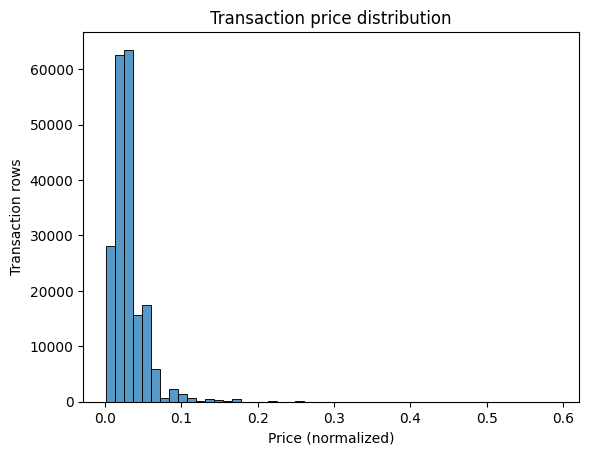

In [7]:
# 히스토그램: 가격 분포
시본.histplot(분석표['price'], bins=50); 그래프.title('Transaction price distribution'); 그래프.xlabel('Price (normalized)'); 그래프.ylabel('Transaction rows'); 그래프.show()

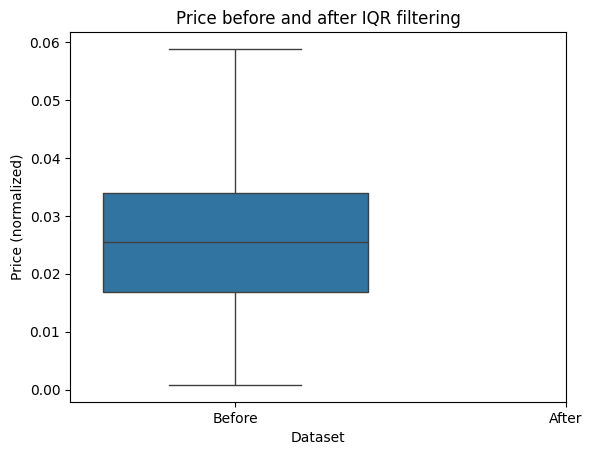

In [8]:
# 박스플롯: IQR 후보 제외 전후
시본.boxplot(data=[분석표['price'].dropna(),분석표.loc[~이상치결과['mask'],'price'].dropna()]); 그래프.xticks([0,1],['Before','After']); 그래프.title('Price before and after IQR filtering'); 그래프.xlabel('Dataset'); 그래프.ylabel('Price (normalized)'); 그래프.show()

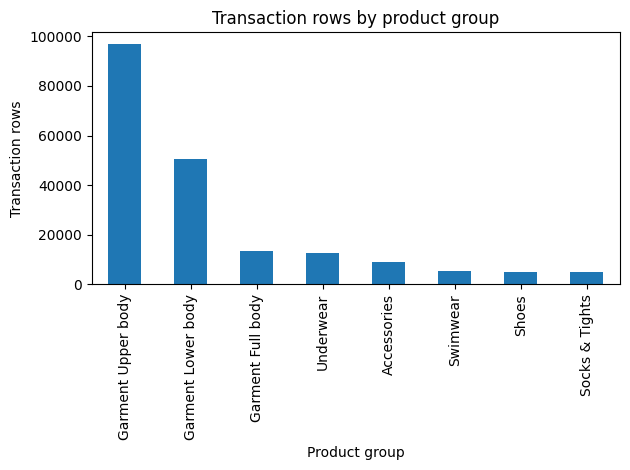

In [9]:
# 막대그래프: 상품군별 거래 수
개수=분석표['product_group_name'].value_counts().head(8); 개수.plot.bar(); 그래프.title('Transaction rows by product group'); 그래프.xlabel('Product group'); 그래프.ylabel('Transaction rows'); 그래프.tight_layout(); 그래프.show()

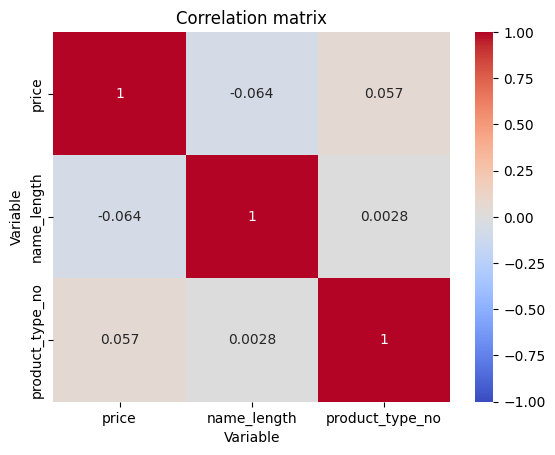

두 번째 상관계수 price vs product_type_no: 0.056936242669706434 (상품 유형 번호는 임의 코드이므로 실질 해석에 주의)


In [10]:
# 히트맵: 수치형 변수의 상관관계
상관행렬=분석표[['price','name_length','product_type_no']].corr(); 시본.heatmap(상관행렬,annot=True,cmap='coolwarm',vmin=-1,vmax=1); 그래프.title('Correlation matrix'); 그래프.xlabel('Variable'); 그래프.ylabel('Variable'); 그래프.show()
print('두 번째 상관계수 price vs product_type_no:',상관행렬.loc['price','product_type_no'], '(상품 유형 번호는 임의 코드이므로 실질 해석에 주의)')

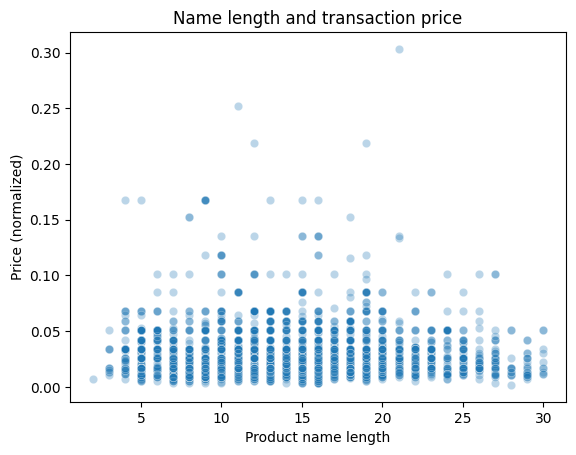

In [11]:
# 산점도: 이름 길이와 가격
시본.scatterplot(data=분석표.sample(min(3000,len(분석표)),random_state=42),x='name_length',y='price',alpha=.3); 그래프.title('Name length and transaction price'); 그래프.xlabel('Product name length'); 그래프.ylabel('Price (normalized)'); 그래프.show()

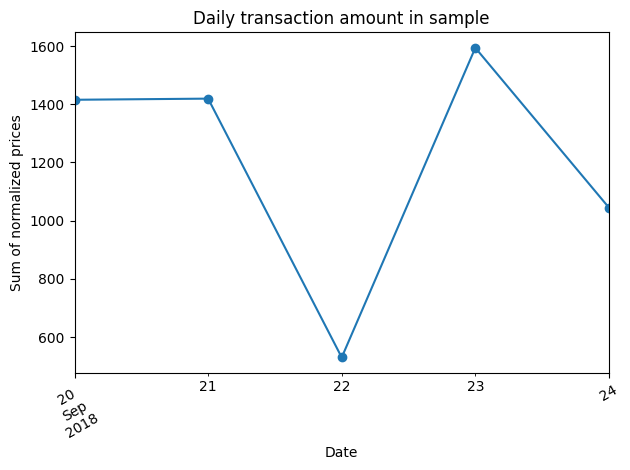

In [12]:
# 라인차트: 표본 기간별 거래금액
일별합계=분석표.groupby('t_dat')['price'].sum(); 일별합계.plot(marker='o'); 그래프.title('Daily transaction amount in sample'); 그래프.xlabel('Date'); 그래프.ylabel('Sum of normalized prices'); 그래프.xticks(rotation=30); 그래프.tight_layout(); 그래프.show()

## RFM 고객 세분화

In [13]:
# 주문번호가 없어 구매일 수를 빈도 대용치로 사용한다.
분석표['purchase_day'] = 분석표['t_dat']
고객지표=분석기.calculate_rfm('customer_id','t_dat','price','purchase_day')
# 최근성의 낮은 값과 빈도·금액의 높은 값이 높은 점수다. 같은 값은 같은 점수를 받는다.
for 열이름 in ['recency','frequency','monetary']:
    순위=고객지표[열이름].rank(method='average',pct=True,ascending=(열이름!='recency'))
    고객지표[열이름+'_score']=넘파이.ceil(순위*4).clip(1,4).astype(int)
# 우선순위를 명시해 한 고객을 한 그룹에만 배정한다.
고객지표['segment']=넘파이.select([(고객지표.recency_score>=3)&(고객지표.frequency_score>=3)&(고객지표.monetary_score>=3), (고객지표.recency_score>=3)&(고객지표.frequency==1), (고객지표.recency_score<=2), (고객지표.frequency_score>=3)],['VIP','Recent one-day','Older activity','Repeat'],default='Other')
요약표=고객지표.groupby('segment').agg(customers=('customer_id','size'),mean_recency=('recency','mean'),mean_days=('frequency','mean'),mean_monetary=('monetary','mean'))
print('기준일:',분석표.t_dat.max(),'고객:',len(고객지표)); print(요약표); 고객지표.head()

기준일: 2018-09-24 00:00:00 고객: 51527
                customers  mean_recency  mean_days  mean_monetary
segment                                                          
Older activity      25060      3.486233   1.025898       0.103544
Recent one-day      23794      0.856813   1.000000       0.119507
Repeat                443      0.740406   2.049661       0.053963
VIP                  2230      0.714798   2.102691       0.242831


,customer_id,last_order,frequency,monetary,recency,recency_score,frequency_score,monetary_score,segment
0,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,2018-09-21,1,0.127068,3,2,2,3,Older activity
1,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,2018-09-24,2,0.132153,0,4,4,3,VIP
2,00007d2de826758b65a93dd24ce629ed66842531df6699...,2018-09-23,2,0.147305,1,3,4,4,VIP
3,00025f8226be50dcab09402a2cacd520a99e112fe01fdd...,2018-09-24,1,0.025407,0,4,2,1,Recent one-day
4,0003abe64294e66a6310c3436fa9e5b754cc5603deef4f...,2018-09-22,1,0.118576,2,3,2,3,Recent one-day


## 해석과 한계
- 가격은 데이터셋에 기록된 상대값으로, 통화 금액이라고 단정하지 않는다.
- 거래 표본은 단 5일로 신규 가입·실제 이탈 및 장기 충성도를 판정할 수 없다. RFM 빈도는 구매일 수이며 주문 횟수가 아니다.
- 상품 유형 번호는 범주 코드이므로 그 숫자와 가격 사이의 상관계수는 인과관계나 의미 있는 수치 관계로 해석하지 않는다.
- 이미지 분석은 상품 40장에 국한되며 원본 이미지들의 연결·대표성을 검토해야 한다.